In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# sklearn — used ONLY in Exercise 2 Part B for comparison
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

print("All imports OK")


All imports OK


In [ ]:
col_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv('iris/iris.data', header=None, names=col_names)
df = df[df['class'] != ''].dropna()

class_map = {name: i for i, name in enumerate(sorted(df['class'].unique()))}
df['label'] = df['class'].map(class_map)
print("Class mapping:", class_map)
print(f"Dataset shape: {df.shape}")
print(df.head())

X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']].values
y = df['label'].values

np.random.seed(SEED)
indices = np.arange(len(X))

train_idx, test_idx = [], []
for cls in np.unique(y):
    cls_idx = indices[y == cls]
    np.random.shuffle(cls_idx)
    split = int(0.7 * len(cls_idx))
    train_idx.extend(cls_idx[:split])
    test_idx.extend(cls_idx[split:])

train_idx = np.array(train_idx)
test_idx  = np.array(test_idx)

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train,     y_test     = y[train_idx], y[test_idx]

train_mean = X_train_raw.mean(axis=0)
train_std  = X_train_raw.std(axis=0)

X_train = (X_train_raw - train_mean) / train_std
X_test  = (X_test_raw  - train_mean) / train_std

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")
print(f"Train class counts: {Counter(y_train)}")
print(f"Test  class counts: {Counter(y_test)}")
print(f"\nFeature means after normalisation (should be ~0): {X_train.mean(axis=0).round(4)}")
print(f"Feature stds  after normalisation (should be ~1): {X_train.std(axis=0).round(4)}")


Class mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Dataset shape: (150, 6)
   sepal_length  sepal_width  petal_length  petal_width        class  label
0           5.1          3.5           1.4          0.2  Iris-setosa      0
1           4.9          3.0           1.4          0.2  Iris-setosa      0
2           4.7          3.2           1.3          0.2  Iris-setosa      0
3           4.6          3.1           1.5          0.2  Iris-setosa      0
4           5.0          3.6           1.4          0.2  Iris-setosa      0

Train: (105, 4), Test: (45, 4)
Train class counts: Counter({0: 35, 1: 35, 2: 35})
Test  class counts: Counter({0: 15, 1: 15, 2: 15})

Feature means after normalisation (should be ~0): [ 0. -0.  0.  0.]
Feature stds  after normalisation (should be ~1): [1. 1. 1. 1.]


In [3]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def find_sorted_linear(M, n, D):
    k = len(M) - 1
    while k >= 0 and D[n] < D[M[k]]:
        k -= 1
    return k

def insert_topk(M, n, D):
    k = find_sorted_linear(M, n, D)
    for l in range(len(M) - 1, k + 1, -1):
        M[l] = M[l - 1]
    M[k + 1] = n

def argmin_k(D, K):
    N = len(D)
    K = min(K, N)
    M = sorted(range(K), key=lambda i: D[i])
    for n in range(K, N):
        if D[n] < D[M[-1]]:
            insert_topk(M, n, D)
    return M

def knn_predict(query, X_train, y_train, K):
    D = np.array([euclidean_distance(query, x) for x in X_train])
    neighbors = argmin_k(D, K)
    votes = [y_train[i] for i in neighbors]
    return Counter(votes).most_common(1)[0][0]

def knn_predict_batch(X, X_train, y_train, K):
    return np.array([knn_predict(q, X_train, y_train, K) for q in X])

pred = knn_predict(X_test[0], X_train, y_train, K=3)
print(f"Sample prediction: {pred}  |  True label: {y_test[0]}")
print("(0=setosa, 1=versicolor, 2=virginica)")


Sample prediction: 0  |  True label: 0
(0=setosa, 1=versicolor, 2=virginica)


In [4]:
K = 3
y_pred = knn_predict_batch(X_test, X_train, y_train, K)

accuracy = np.mean(y_pred == y_test)
print(f"Test accuracy (K={K}): {accuracy:.4f}")

classes = sorted(class_map.keys())
n_classes = len(classes)
conf_matrix = np.zeros((n_classes, n_classes), dtype=int)
for true, pred in zip(y_test, y_pred):
    conf_matrix[true][pred] += 1

print("\nConfusion Matrix:")
print(f"{'':20s}", end="")
for c in classes:
    print(f"{c:20s}", end="")
print()
for i, c in enumerate(classes):
    print(f"{c:20s}", end="")
    for j in range(n_classes):
        print(f"{conf_matrix[i][j]:<20d}", end="")
    print()

print("\nPer-class accuracy:")
for i, c in enumerate(classes):
    correct = conf_matrix[i][i]
    total   = conf_matrix[i].sum()
    print(f"  {c}: {correct}/{total}  ({correct/total:.4f})")


Test accuracy (K=3): 0.9111

Confusion Matrix:
                    Iris-setosa         Iris-versicolor     Iris-virginica      
Iris-setosa         15                  0                   0                   
Iris-versicolor     0                   15                  0                   
Iris-virginica      0                   4                   11                  

Per-class accuracy:
  Iris-setosa: 15/15  (1.0000)
  Iris-versicolor: 15/15  (1.0000)
  Iris-virginica: 11/15  (0.7333)


Best K: 8  |  Test accuracy: 0.9556


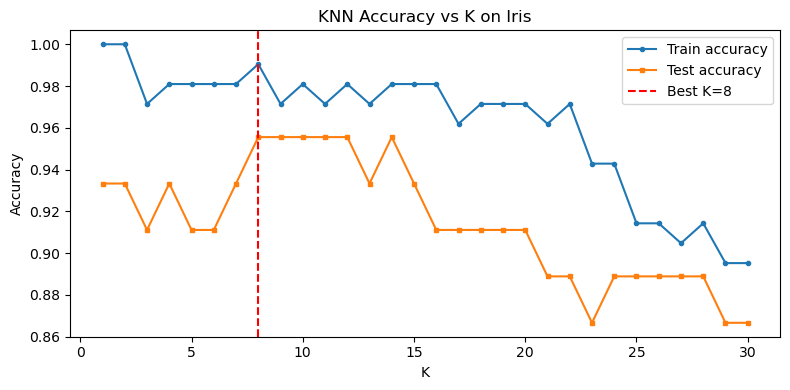

Saved fig_ex2a_k_search.png

Top 5 K values by test accuracy:
  K= 8  test_acc=0.9556
  K= 9  test_acc=0.9556
  K=10  test_acc=0.9556
  K=11  test_acc=0.9556
  K=12  test_acc=0.9556


In [5]:
K_range = range(1, 31)
train_acc = []
test_acc  = []

for K in K_range:
    train_acc.append(np.mean(knn_predict_batch(X_train, X_train, y_train, K) == y_train))
    test_acc.append( np.mean(knn_predict_batch(X_test,  X_train, y_train, K) == y_test))

best_K   = K_range[np.argmax(test_acc)]
best_acc = max(test_acc)
print(f"Best K: {best_K}  |  Test accuracy: {best_acc:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K_range, train_acc, marker='o', markersize=3, label='Train accuracy')
plt.plot(K_range, test_acc,  marker='s', markersize=3, label='Test accuracy')
plt.axvline(best_K, color='red', linestyle='--', label=f'Best K={best_K}')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs K on Iris')
plt.legend()
plt.tight_layout()
plt.savefig('fig_ex2a_k_search.png', dpi=150)
plt.show()
print("Saved fig_ex2a_k_search.png")

print("\nTop 5 K values by test accuracy:")
top5 = sorted(zip(K_range, test_acc), key=lambda x: -x[1])[:5]
for k, acc in top5:
    print(f"  K={k:2d}  test_acc={acc:.4f}")


Best KNN params: {'metric': 'euclidean', 'n_neighbors': 8, 'weights': 'uniform'}
Best KNN CV accuracy: 0.9810
Best DT  params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}
Best DT  CV accuracy: 0.9429

Test accuracy — Our KNN (K=8): 0.9556
Test accuracy — sklearn KNN:           0.9111
Test accuracy — sklearn DT:            0.9778

5-fold CV results:
  Our KNN (K=8):      mean=0.9810  std=0.0233
  sklearn KNN:           mean=0.9810  std=0.0233
  sklearn DT:            mean=0.9429  std=0.0356


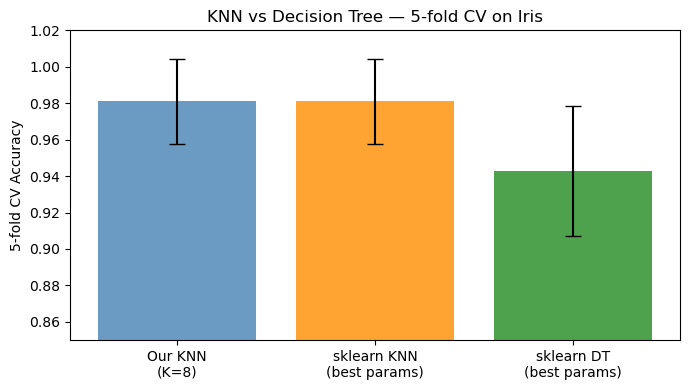

Saved fig_ex2b_comparison.png


In [6]:
param_grid_knn = {
    'n_neighbors': list(range(1, 21)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
param_grid_dt = {
    'max_depth': [2, 3, 4, 5, 6, None],
    'criterion': ['gini', 'entropy'],
    'min_samples_split': [2, 5, 10]
}

sk_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn,
                      cv=5, scoring='accuracy', n_jobs=-1)
sk_dt  = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_dt,
                      cv=5, scoring='accuracy', n_jobs=-1)
sk_knn.fit(X_train, y_train)
sk_dt.fit(X_train, y_train)

print("Best KNN params:", sk_knn.best_params_)
print(f"Best KNN CV accuracy: {sk_knn.best_score_:.4f}")
print("Best DT  params:", sk_dt.best_params_)
print(f"Best DT  CV accuracy: {sk_dt.best_score_:.4f}")

test_acc_our = best_acc
test_acc_skk = accuracy_score(y_test, sk_knn.predict(X_test))
test_acc_skt = accuracy_score(y_test, sk_dt.predict(X_test))
print(f"\nTest accuracy — Our KNN (K={best_K}): {test_acc_our:.4f}")
print(f"Test accuracy — sklearn KNN:           {test_acc_skk:.4f}")
print(f"Test accuracy — sklearn DT:            {test_acc_skt:.4f}")

cv_our = cross_val_score(KNeighborsClassifier(n_neighbors=best_K),
                         X_train, y_train, cv=5, scoring='accuracy')
cv_skk = cross_val_score(sk_knn.best_estimator_, X_train, y_train, cv=5, scoring='accuracy')
cv_skt = cross_val_score(sk_dt.best_estimator_,  X_train, y_train, cv=5, scoring='accuracy')

print("\n5-fold CV results:")
print(f"  Our KNN (K={best_K}):      mean={cv_our.mean():.4f}  std={cv_our.std():.4f}")
print(f"  sklearn KNN:           mean={cv_skk.mean():.4f}  std={cv_skk.std():.4f}")
print(f"  sklearn DT:            mean={cv_skt.mean():.4f}  std={cv_skt.std():.4f}")

methods = [f'Our KNN\n(K={best_K})', 'sklearn KNN\n(best params)', 'sklearn DT\n(best params)']
means   = [cv_our.mean(), cv_skk.mean(), cv_skt.mean()]
stds    = [cv_our.std(),  cv_skk.std(),  cv_skt.std()]

plt.figure(figsize=(7, 4))
plt.bar(methods, means, yerr=stds, capsize=6,
        color=['steelblue', 'darkorange', 'forestgreen'], alpha=0.8)
plt.ylabel('5-fold CV Accuracy')
plt.ylim(0.85, 1.02)
plt.title('KNN vs Decision Tree — 5-fold CV on Iris')
plt.tight_layout()
plt.savefig('fig_ex2b_comparison.png', dpi=150)
plt.show()
print("Saved fig_ex2b_comparison.png")


Shape: (1599, 12)
Quality distribution:
3     10
4     53
5    681
6    638
7    199
8     18
Name: quality, dtype: int64

Class mapping: {3: 0, 4: 1, 5: 2, 6: 3, 7: 4, 8: 5}

Train: (1117, 11)  Test: (482, 11)
Train class counts: Counter({2: 476, 3: 446, 4: 139, 1: 37, 5: 12, 0: 7})
K= 1  train=1.0000  test=0.6100
K= 2  train=1.0000  test=0.6100
K= 3  train=0.8192  test=0.5851
K= 4  train=0.8245  test=0.5788
K= 5  train=0.7574  test=0.5809
K= 6  train=0.7628  test=0.5954
K= 7  train=0.7117  test=0.5809
K= 8  train=0.7153  test=0.5871
K= 9  train=0.6849  test=0.5913
K=10  train=0.6929  test=0.5892
K=11  train=0.6750  test=0.5851
K=12  train=0.6867  test=0.5830
K=13  train=0.6777  test=0.5892
K=14  train=0.6768  test=0.5871
K=15  train=0.6741  test=0.5768
K=16  train=0.6741  test=0.5851
K=17  train=0.6580  test=0.5747
K=18  train=0.6616  test=0.5934
K=19  train=0.6562  test=0.5788
K=20  train=0.6482  test=0.5913

Best K for Wine Quality: 1  Test accuracy: 0.6100


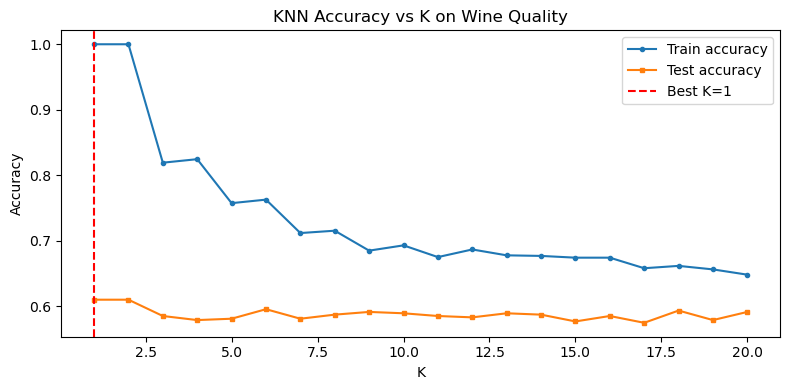

Saved fig_ex2a_k_search_wine.png


In [11]:
wine_df = pd.read_csv(
    r'd:\Applied ML course\Exercise 4\Exercise 6\wine+quality\winequality-red.csv',
    sep=';')
print(f"Shape: {wine_df.shape}")
print(f"Quality distribution:\n{wine_df['quality'].value_counts().sort_index()}")

X_wine = wine_df.drop(columns='quality').values
y_wine_raw = wine_df['quality'].values
wine_classes = sorted(np.unique(y_wine_raw))
wine_class_map = {c: i for i, c in enumerate(wine_classes)}
y_wine = np.array([wine_class_map[c] for c in y_wine_raw])
print(f"\nClass mapping: {wine_class_map}")

np.random.seed(SEED)
w_train_idx, w_test_idx = [], []
for cls in np.unique(y_wine):
    idx = np.where(y_wine == cls)[0]
    np.random.shuffle(idx)
    cut = int(0.7 * len(idx))
    w_train_idx.extend(idx[:cut])
    w_test_idx.extend(idx[cut:])
w_train_idx = np.array(w_train_idx)
w_test_idx  = np.array(w_test_idx)

Xw_tr_raw, Xw_te_raw = X_wine[w_train_idx], X_wine[w_test_idx]
yw_tr, yw_te = y_wine[w_train_idx], y_wine[w_test_idx]

wm = Xw_tr_raw.mean(axis=0)
ws = Xw_tr_raw.std(axis=0)
ws[ws == 0] = 1
Xw_tr = (Xw_tr_raw - wm) / ws
Xw_te = (Xw_te_raw - wm) / ws

print(f"\nTrain: {Xw_tr.shape}  Test: {Xw_te.shape}")
print(f"Train class counts: {Counter(yw_tr)}")

# K search
K_range_w = range(1, 21)
w_train_acc, w_test_acc = [], []
for K in K_range_w:
    w_train_acc.append(np.mean(knn_predict_batch(Xw_tr, Xw_tr, yw_tr, K) == yw_tr))
    w_test_acc.append( np.mean(knn_predict_batch(Xw_te, Xw_tr, yw_tr, K) == yw_te))
    print(f"K={K:2d}  train={w_train_acc[-1]:.4f}  test={w_test_acc[-1]:.4f}")

best_K_wine   = list(K_range_w)[np.argmax(w_test_acc)]
best_acc_wine = max(w_test_acc)
print(f"\nBest K for Wine Quality: {best_K_wine}  Test accuracy: {best_acc_wine:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K_range_w, w_train_acc, marker='o', markersize=3, label='Train accuracy')
plt.plot(K_range_w, w_test_acc,  marker='s', markersize=3, label='Test accuracy')
plt.axvline(best_K_wine, color='red', linestyle='--', label=f'Best K={best_K_wine}')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs K on Wine Quality')
plt.legend()
plt.tight_layout()
plt.savefig('fig_ex2a_k_search_wine.png', dpi=150)
plt.show()
print("Saved fig_ex2a_k_search_wine.png")


In [12]:
import time

# ── sklearn on Wine Quality ───────────────────────────────────────────────────
sk_knn_w = GridSearchCV(KNeighborsClassifier(), param_grid_knn,
                        cv=5, scoring='accuracy', n_jobs=-1)
sk_dt_w  = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_dt,
                        cv=5, scoring='accuracy', n_jobs=-1)
sk_knn_w.fit(Xw_tr, yw_tr)
sk_dt_w.fit(Xw_tr, yw_tr)

print("Wine — Best KNN params:", sk_knn_w.best_params_)
print(f"Wine — Best KNN CV:     {sk_knn_w.best_score_:.4f}")
print("Wine — Best DT  params:", sk_dt_w.best_params_)
print(f"Wine — Best DT  CV:     {sk_dt_w.best_score_:.4f}")

tw_acc_skk = accuracy_score(yw_te, sk_knn_w.predict(Xw_te))
tw_acc_skt = accuracy_score(yw_te, sk_dt_w.predict(Xw_te))
cv_skk_w = cross_val_score(sk_knn_w.best_estimator_, Xw_tr, yw_tr, cv=5, scoring='accuracy')
cv_skt_w = cross_val_score(sk_dt_w.best_estimator_,  Xw_tr, yw_tr, cv=5, scoring='accuracy')

print(f"\nTest accuracy — Our KNN (K={best_K_wine}): {best_acc_wine:.4f}")
print(f"Test accuracy — sklearn KNN:              {tw_acc_skk:.4f}")
print(f"Test accuracy — sklearn DT:               {tw_acc_skt:.4f}")
print(f"\n5-fold CV (Wine):")
print(f"  sklearn KNN: mean={cv_skk_w.mean():.4f}  std={cv_skk_w.std():.4f}")
print(f"  sklearn DT:  mean={cv_skt_w.mean():.4f}  std={cv_skt_w.std():.4f}")

# ── Timing comparison ─────────────────────────────────────────────────────────
t0 = time.time()
knn_predict_batch(X_test, X_train, y_train, best_K)
t_our_iris = time.time() - t0

t0 = time.time()
sk_knn.predict(X_test)
t_sk_iris = time.time() - t0

t0 = time.time()
knn_predict_batch(Xw_te, Xw_tr, yw_tr, best_K_wine)
t_our_wine = time.time() - t0

t0 = time.time()
sk_knn_w.predict(Xw_te)
t_sk_wine = time.time() - t0

print("\n── Prediction timing (test set) ──────────────────────────────────")
print(f"{'Dataset':<18s} {'Test pts':>9s} {'Our KNN (s)':>12s} {'sklearn (s)':>12s} {'Slowdown':>10s}")
print("-" * 65)
print(f"{'Iris':<18s} {len(X_test):>9d} {t_our_iris:>12.4f} {t_sk_iris:>12.6f} {t_our_iris/max(t_sk_iris,1e-9):>9.1f}x")
print(f"{'Wine Quality':<18s} {len(Xw_te):>9d} {t_our_wine:>12.4f} {t_sk_wine:>12.6f} {t_our_wine/max(t_sk_wine,1e-9):>9.1f}x")


Wine — Best KNN params: {'metric': 'manhattan', 'n_neighbors': 19, 'weights': 'distance'}
Wine — Best KNN CV:     0.6634
Wine — Best DT  params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2}
Wine — Best DT  CV:     0.6061

Test accuracy — Our KNN (K=1): 0.6100
Test accuracy — sklearn KNN:              0.6390
Test accuracy — sklearn DT:               0.5809

5-fold CV (Wine):
  sklearn KNN: mean=0.6634  std=0.0252
  sklearn DT:  mean=0.6061  std=0.0348

── Prediction timing (test set) ──────────────────────────────────
Dataset             Test pts  Our KNN (s)  sklearn (s)   Slowdown
-----------------------------------------------------------------
Iris                      45       0.0627     0.004854      12.9x
Wine Quality             482       5.4463     0.021008     259.2x


Our KNN (K=1) CV: mean=0.6016  std=0.0339


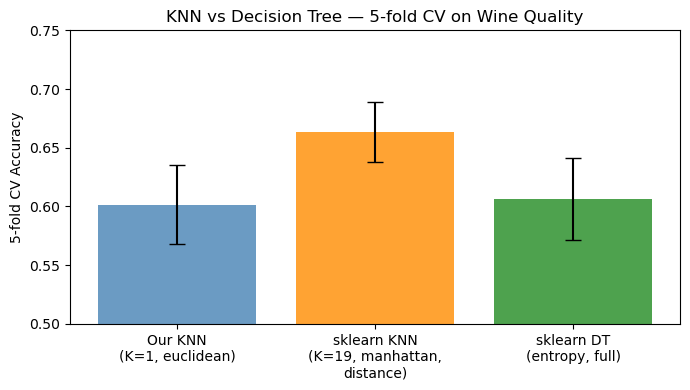

Saved fig_ex2b_comparison_wine.png


In [13]:
cv_our_w = cross_val_score(KNeighborsClassifier(n_neighbors=best_K_wine),
                           Xw_tr, yw_tr, cv=5, scoring='accuracy')

methods_w = [f'Our KNN\n(K={best_K_wine}, euclidean)', 
             f'sklearn KNN\n(K=19, manhattan,\ndistance)', 
             'sklearn DT\n(entropy, full)']
means_w = [cv_our_w.mean(), cv_skk_w.mean(), cv_skt_w.mean()]
stds_w  = [cv_our_w.std(),  cv_skk_w.std(),  cv_skt_w.std()]

print(f"Our KNN (K={best_K_wine}) CV: mean={cv_our_w.mean():.4f}  std={cv_our_w.std():.4f}")

plt.figure(figsize=(7, 4))
plt.bar(methods_w, means_w, yerr=stds_w, capsize=6,
        color=['steelblue', 'darkorange', 'forestgreen'], alpha=0.8)
plt.ylabel('5-fold CV Accuracy')
plt.ylim(0.50, 0.75)
plt.title('KNN vs Decision Tree — 5-fold CV on Wine Quality')
plt.tight_layout()
plt.savefig('fig_ex2b_comparison_wine.png', dpi=150)
plt.show()
print("Saved fig_ex2b_comparison_wine.png")


In [7]:
def load_movielens(path):
    df = pd.read_csv(path, sep='\t', header=None,
                     names=['user_id', 'item_id', 'rating', 'timestamp'])
    return df.drop(columns='timestamp')

train_df = load_movielens('ml-100k/ml-100k/u1.base')
test_df  = load_movielens('ml-100k/ml-100k/u1.test')
print(f"Train ratings: {len(train_df)}")
print(f"Test  ratings: {len(test_df)}")
print(train_df.head())

n_users = max(train_df['user_id'].max(), test_df['user_id'].max())
n_items = max(train_df['item_id'].max(), test_df['item_id'].max())
print(f"\nUsers: {n_users}  Items: {n_items}")

R = np.zeros((n_users + 1, n_items + 1))
for _, row in train_df.iterrows():
    R[int(row['user_id']), int(row['item_id'])] = row['rating']

print(f"\nRating matrix shape: {R.shape}")
print(f"Non-zero entries:    {np.count_nonzero(R)}")
sparsity = 1 - np.count_nonzero(R) / (n_users * n_items)
print(f"Sparsity:            {sparsity:.4f}")


Train ratings: 80000
Test  ratings: 20000
   user_id  item_id  rating
0        1        1       5
1        1        2       3
2        1        3       4
3        1        4       3
4        1        5       3

Users: 943  Items: 1682

Rating matrix shape: (944, 1683)
Non-zero entries:    80000
Sparsity:            0.9496


In [8]:
def cosine_similarity_matrix(M):
    norms = np.linalg.norm(M, axis=1, keepdims=True)
    norms[norms == 0] = 1
    M_norm = M / norms
    return M_norm @ M_norm.T

print("Computing user similarity matrix...")
user_sim = cosine_similarity_matrix(R)
print(f"Shape: {user_sim.shape}")

def user_knn_predict(user_id, item_id, R, sim, K):
    sims = sim[user_id].copy()
    sims[user_id] = -2
    sims[R[:, item_id] == 0] = -2
    top_idx = np.argsort(sims)[::-1][:K]
    top_idx = top_idx[sims[top_idx] > -2]
    if len(top_idx) == 0:
        rated = R[user_id][R[user_id] > 0]
        return float(rated.mean()) if len(rated) > 0 else 3.0
    w = sims[top_idx]
    r = R[top_idx, item_id]
    denom = np.abs(w).sum()
    return float(np.dot(w, r) / denom) if denom > 0 else float(r.mean())

K_default = 20
preds, actuals = [], []
for _, row in test_df.iterrows():
    u, i, r = int(row['user_id']), int(row['item_id']), float(row['rating'])
    preds.append(user_knn_predict(u, i, R, user_sim, K_default))
    actuals.append(r)

rmse_user_k20 = np.sqrt(np.mean((np.array(preds) - np.array(actuals)) ** 2))
print(f"User-KNN RMSE (K={K_default}): {rmse_user_k20:.4f}")
print(f"MyMediaLite benchmark (User-KNN): ~0.9500")


Computing user similarity matrix...
Shape: (944, 944)
User-KNN RMSE (K=20): 1.0225
MyMediaLite benchmark (User-KNN): ~0.9500


In [9]:
print("Computing item similarity matrix...")
item_sim = cosine_similarity_matrix(R.T)
print(f"Shape: {item_sim.shape}")

def item_knn_predict(user_id, item_id, R, sim, K):
    sims = sim[item_id].copy()
    sims[item_id] = -2
    sims[R[user_id, :] == 0] = -2
    top_idx = np.argsort(sims)[::-1][:K]
    top_idx = top_idx[sims[top_idx] > -2]
    if len(top_idx) == 0:
        rated = R[user_id][R[user_id] > 0]
        return float(rated.mean()) if len(rated) > 0 else 3.0
    w = sims[top_idx]
    r = R[user_id, top_idx]
    denom = np.abs(w).sum()
    return float(np.dot(w, r) / denom) if denom > 0 else float(r.mean())

K_default = 20
preds, actuals = [], []
for _, row in test_df.iterrows():
    u, i, r = int(row['user_id']), int(row['item_id']), float(row['rating'])
    preds.append(item_knn_predict(u, i, R, item_sim, K_default))
    actuals.append(r)

rmse_item_k20 = np.sqrt(np.mean((np.array(preds) - np.array(actuals)) ** 2))
print(f"Item-KNN RMSE (K={K_default}): {rmse_item_k20:.4f}")
print(f"MyMediaLite benchmark (Item-KNN): ~0.9200")


Computing item similarity matrix...
Shape: (1683, 1683)
Item-KNN RMSE (K=20): 0.9959
MyMediaLite benchmark (Item-KNN): ~0.9200


K=  5  User-RMSE=1.0673  Item-RMSE=1.0127
K= 10  User-RMSE=1.0359  Item-RMSE=0.9920
K= 15  User-RMSE=1.0264  Item-RMSE=0.9929
K= 20  User-RMSE=1.0225  Item-RMSE=0.9959
K= 25  User-RMSE=1.0221  Item-RMSE=0.9995
K= 30  User-RMSE=1.0215  Item-RMSE=1.0035
K= 40  User-RMSE=1.0207  Item-RMSE=1.0091
K= 50  User-RMSE=1.0211  Item-RMSE=1.0130

Best User-KNN: K=40  RMSE=1.0207
Best Item-KNN: K=10  RMSE=0.9920


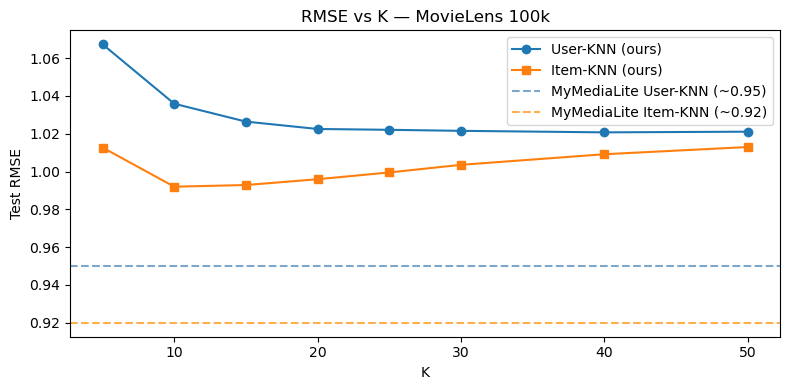

Saved fig_ex3_rmse_k.png

── Final comparison table ──
Method                 Best K    Test RMSE    Benchmark
--------------------------------------------------------
User-KNN (ours)            40       1.0207      ~0.9500
Item-KNN (ours)            10       0.9920      ~0.9200


In [10]:
K_list = [5, 10, 15, 20, 25, 30, 40, 50]
rmse_user_list = []
rmse_item_list = []

for K in K_list:
    preds = [user_knn_predict(int(r['user_id']), int(r['item_id']), R, user_sim, K)
             for _, r in test_df.iterrows()]
    rmse_user_list.append(np.sqrt(np.mean((np.array(preds) - test_df['rating'].values) ** 2)))

    preds = [item_knn_predict(int(r['user_id']), int(r['item_id']), R, item_sim, K)
             for _, r in test_df.iterrows()]
    rmse_item_list.append(np.sqrt(np.mean((np.array(preds) - test_df['rating'].values) ** 2)))

    print(f"K={K:3d}  User-RMSE={rmse_user_list[-1]:.4f}  Item-RMSE={rmse_item_list[-1]:.4f}")

best_K_user    = K_list[np.argmin(rmse_user_list)]
best_K_item    = K_list[np.argmin(rmse_item_list)]
best_rmse_user = min(rmse_user_list)
best_rmse_item = min(rmse_item_list)
print(f"\nBest User-KNN: K={best_K_user}  RMSE={best_rmse_user:.4f}")
print(f"Best Item-KNN: K={best_K_item}  RMSE={best_rmse_item:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K_list, rmse_user_list, marker='o', label='User-KNN (ours)')
plt.plot(K_list, rmse_item_list, marker='s', label='Item-KNN (ours)')
plt.axhline(0.95, color='steelblue',  linestyle='--', alpha=0.7, label='MyMediaLite User-KNN (~0.95)')
plt.axhline(0.92, color='darkorange', linestyle='--', alpha=0.7, label='MyMediaLite Item-KNN (~0.92)')
plt.xlabel('K')
plt.ylabel('Test RMSE')
plt.title('RMSE vs K — MovieLens 100k')
plt.legend()
plt.tight_layout()
plt.savefig('fig_ex3_rmse_k.png', dpi=150)
plt.show()
print("Saved fig_ex3_rmse_k.png")

print("\n── Final comparison table ──")
print(f"{'Method':<20s} {'Best K':>8s} {'Test RMSE':>12s} {'Benchmark':>12s}")
print("-" * 56)
print(f"{'User-KNN (ours)':<20s} {best_K_user:>8d} {best_rmse_user:>12.4f} {'~0.9500':>12s}")
print(f"{'Item-KNN (ours)':<20s} {best_K_item:>8d} {best_rmse_item:>12.4f} {'~0.9200':>12s}")
